# EVCharge Analytics
## Exploratory Data Analysis of Electric Vehicle Charging Transactions

### Invoqe Data Analytics Internship — Task 2

This project explores electric vehicle charging transaction data to understand charging patterns, energy demand, charger usage, and session duration.

### Objectives
- Inspect and understand the dataset
- Clean and validate the data
- Perform exploratory data analysis
- Identify charging behavior patterns
- Create meaningful visualizations
- Summarize key findings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

os.makedirs("data", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("data/ev_charging_raw.csv.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 72856
Columns: 13


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), in

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UserID,72856.0,NaN,NaN,NaN,338.164667,553.970996,0.0,0.0,62.0,407.0,2501.0
ChargerID,72856.0,NaN,NaN,NaN,525.489212,569.544469,1.0,107.0,301.0,738.0,2671.0
ChargerCompany,72856.0,NaN,NaN,NaN,0.627443,0.483489,0.0,0.0,1.0,1.0,1.0
Location,72856,14,public area,14082,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChargerType,72856.0,NaN,NaN,NaN,0.20524,0.40388,0.0,0.0,0.0,0.0,1.0
StartDay,72856,366,2022-08-10,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StartTime,72856,43245,18:28:39,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndDay,72856,365,2022-07-28,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndTime,72856,46710,4:10:01,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StartDatetime,72856,65628,2022-05-16 15:10,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Values,Missing Percentage
UserID,0,0.0
ChargerID,0,0.0
ChargerCompany,0,0.0
Location,0,0.0
ChargerType,0,0.0
StartDay,0,0.0
StartTime,0,0.0
EndDay,0,0.0
EndTime,0,0.0
StartDatetime,0,0.0


In [6]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 13


In [7]:
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows that are completely empty
df_clean = df_clean.dropna(how="all")

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 72856
Cleaned rows: 72843
Rows removed: 13


In [8]:
df_clean.to_csv("data/ev_charging_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
print(df.columns.tolist())
df.head()

['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [10]:
# Check missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Values,Missing Percentage
UserID,0,0.0
ChargerID,0,0.0
ChargerCompany,0,0.0
Location,0,0.0
ChargerType,0,0.0
StartDay,0,0.0
StartTime,0,0.0
EndDay,0,0.0
EndTime,0,0.0
StartDatetime,0,0.0


In [11]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check data types
display(df.dtypes)

Duplicate rows: 13


UserID              int64
ChargerID           int64
ChargerCompany      int64
Location              str
ChargerType         int64
StartDay              str
StartTime             str
EndDay                str
EndTime               str
StartDatetime         str
EndDatetime           str
Duration            int64
Demand            float64
dtype: object

In [12]:
df_clean = df.copy()

# Convert timestamp columns
df_clean["StartDatetime"] = pd.to_datetime(
    df_clean["StartDatetime"], errors="coerce"
)

df_clean["EndDatetime"] = pd.to_datetime(
    df_clean["EndDatetime"], errors="coerce"
)

# Convert numeric columns
numeric_columns = [
    "UserID",
    "ChargerID",
    "ChargerType",
    "Duration",
    "Demand"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column], errors="coerce"
    )

print("Data types converted.")
display(df_clean.dtypes)

Data types converted.


UserID                     int64
ChargerID                  int64
ChargerCompany             int64
Location                     str
ChargerType                int64
StartDay                     str
StartTime                    str
EndDay                       str
EndTime                      str
StartDatetime     datetime64[us]
EndDatetime       datetime64[us]
Duration                   int64
Demand                   float64
dtype: object

In [13]:
original_rows = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows with missing essential values
essential_columns = [
    "StartDatetime",
    "EndDatetime",
    "Duration",
    "Demand",
    "Location"
]

df_clean = df_clean.dropna(subset=essential_columns)

# Keep only valid positive durations and non-negative demand
df_clean = df_clean[
    (df_clean["Duration"] > 0) &
    (df_clean["Demand"] >= 0)
]

# End time should not be earlier than start time
df_clean = df_clean[
    df_clean["EndDatetime"] >= df_clean["StartDatetime"]
]

print("Rows before cleaning:", original_rows)
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", original_rows - len(df_clean))

Rows before cleaning: 72856
Rows after cleaning: 72108
Rows removed: 748


In [14]:
# Extract hour and day information from the start timestamp
df_clean["StartHour"] = df_clean["StartDatetime"].dt.hour

df_clean["DayOfWeek"] = df_clean["StartDatetime"].dt.day_name()

df_clean["Month"] = df_clean["StartDatetime"].dt.month

df_clean["Date"] = df_clean["StartDatetime"].dt.date

# Categorize time of day
def classify_time(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df_clean["TimePeriod"] = df_clean["StartHour"].apply(classify_time)

display(df_clean.head())

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,StartHour,DayOfWeek,Month,Date,TimePeriod
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,Thursday,9,2022-09-15,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,Wednesday,9,2022-09-14,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,Wednesday,9,2022-09-14,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,Thursday,9,2022-09-29,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,Sunday,9,2022-09-25,Evening


In [15]:
df_clean.to_csv("data/ev_charging_cleaned.csv", index=False)

print("Cleaned dataset saved to data/ev_charging_cleaned.csv")
print("Final dataset shape:", df_clean.shape)

Cleaned dataset saved to data/ev_charging_cleaned.csv
Final dataset shape: (72108, 18)


In [28]:
print("Number of charging sessions:", len(df_clean))
print("Unique users:", df_clean["UserID"].nunique())
print("Unique chargers:", df_clean["ChargerID"].nunique())
print("Unique locations:", df_clean["Location"].nunique())

print("\nDuration summary:")
display(df_clean["Duration"].describe())

print("\nDemand summary:")
display(df_clean["Demand"].describe())

Number of charging sessions: 72108
Unique users: 2321
Unique chargers: 2115
Unique locations: 14

Duration summary:


count    72108.000000
mean       152.727867
std        146.359716
min          1.000000
25%         41.000000
50%        114.000000
75%        203.000000
max       1573.000000
Name: Duration, dtype: float64


Demand summary:


count    72108.000000
mean        17.571782
std         13.459642
min          0.010000
25%          7.700000
50%         14.260000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

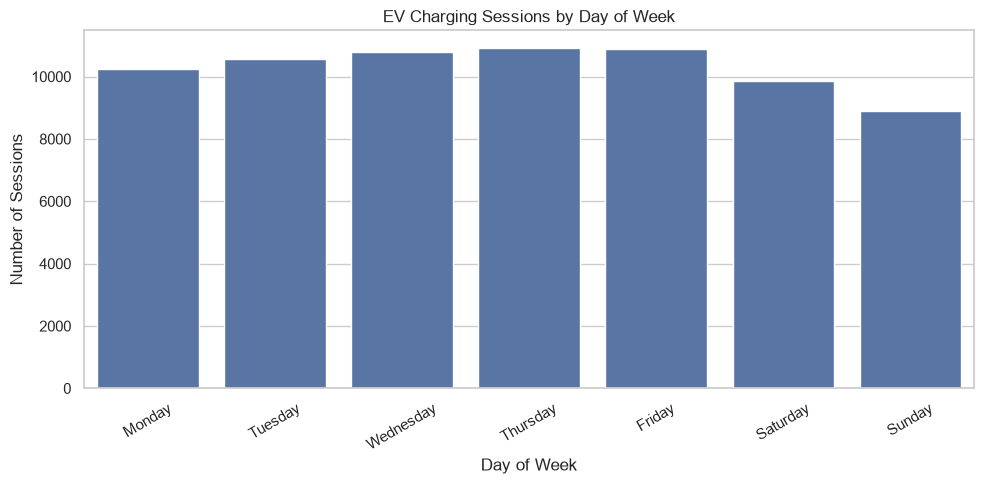

In [29]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

sessions_by_day = (
    df_clean["DayOfWeek"]
    .value_counts()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=sessions_by_day.index,
    y=sessions_by_day.values
)

plt.title("EV Charging Sessions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "visualizations/charging_sessions_by_day.png",
    dpi=300
)
plt.show()

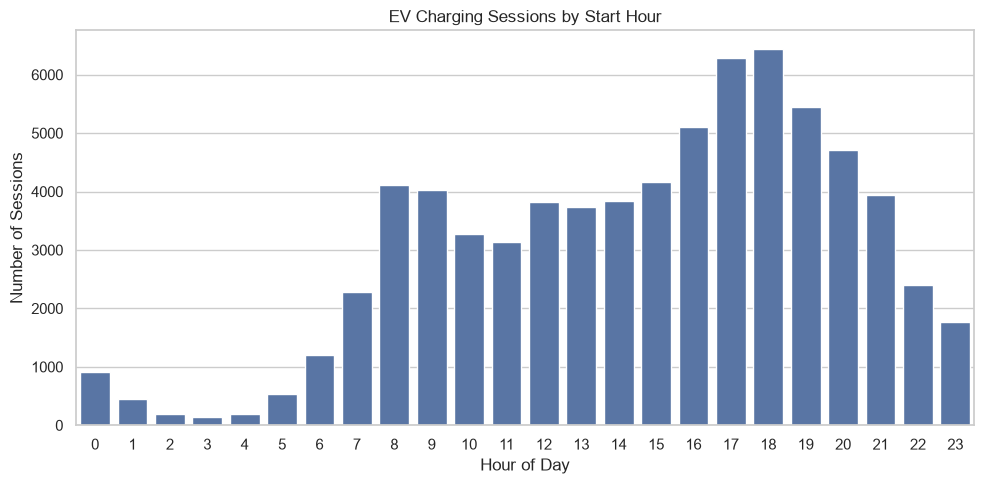

In [30]:
sessions_by_hour = df_clean["StartHour"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=sessions_by_hour.index,
    y=sessions_by_hour.values
)

plt.title("EV Charging Sessions by Start Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Sessions")
plt.xticks(range(0, 24))
plt.tight_layout()

plt.savefig(
    "visualizations/charging_sessions_by_hour.png",
    dpi=300
)
plt.show()

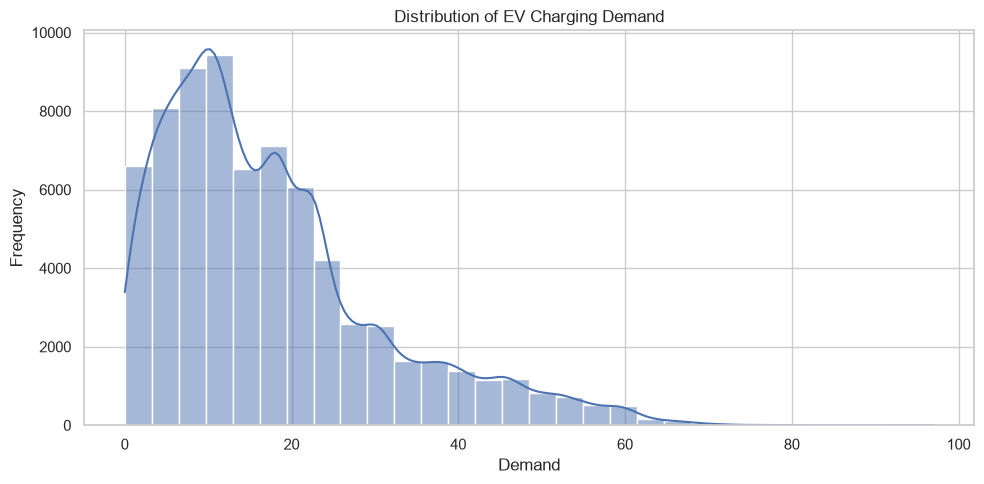

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x="Demand",
    bins=30,
    kde=True
)

plt.title("Distribution of EV Charging Demand")
plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "visualizations/energy_distribution.png",
    dpi=300
)
plt.show()

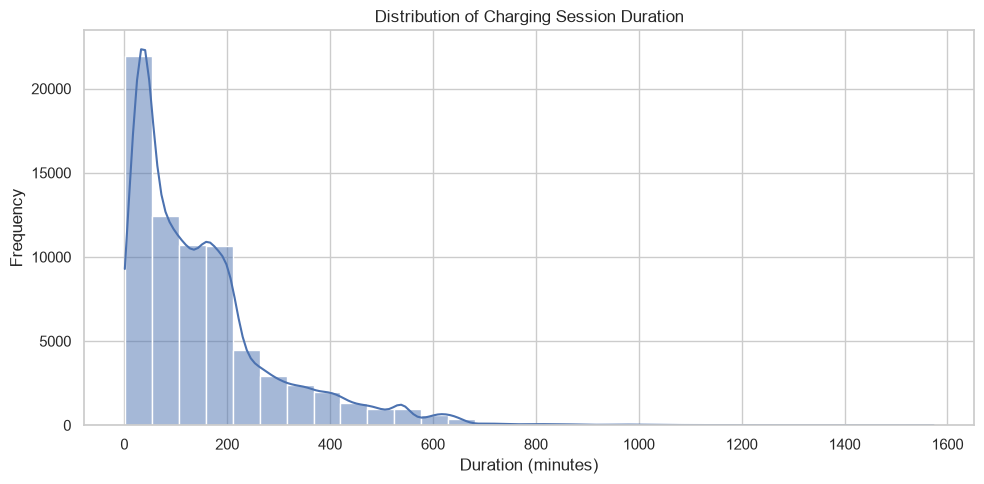

In [32]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x="Duration",
    bins=30,
    kde=True
)

plt.title("Distribution of Charging Session Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "visualizations/charging_duration_distribution.png",
    dpi=300
)
plt.show()

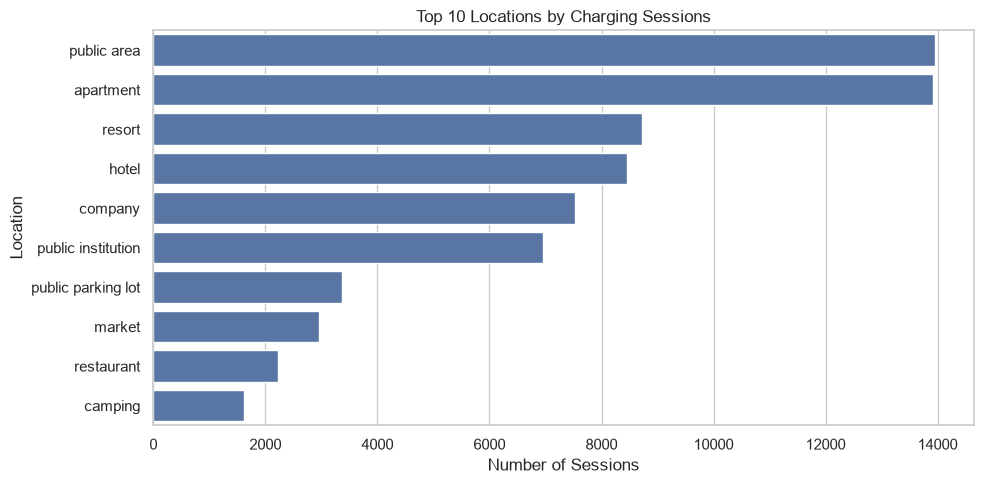

In [33]:
sessions_by_location = (
    df_clean["Location"]
    .value_counts()
    .head(10)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=sessions_by_location.values,
    y=sessions_by_location.index
)

plt.title("Top 10 Locations by Charging Sessions")
plt.xlabel("Number of Sessions")
plt.ylabel("Location")
plt.tight_layout()

plt.savefig(
    "visualizations/sessions_by_location.png",
    dpi=300
)
plt.show()

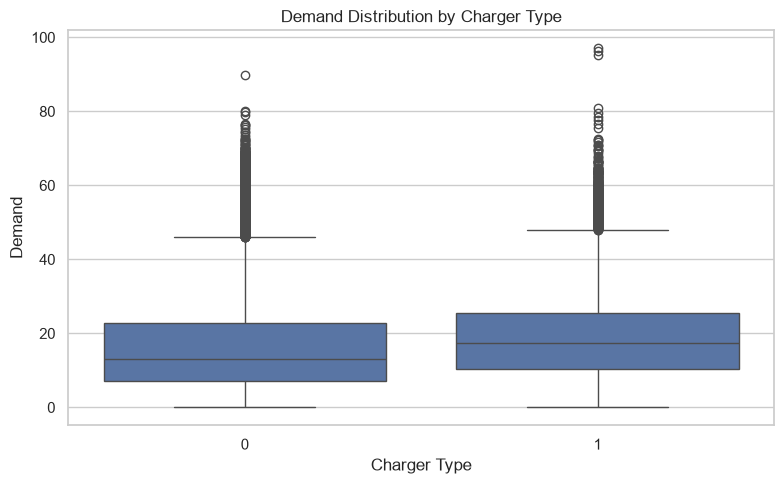

In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="ChargerType",
    y="Demand"
)

plt.title("Demand Distribution by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Demand")
plt.tight_layout()

plt.savefig(
    "visualizations/demand_by_charger_type.png",
    dpi=300
)
plt.show()

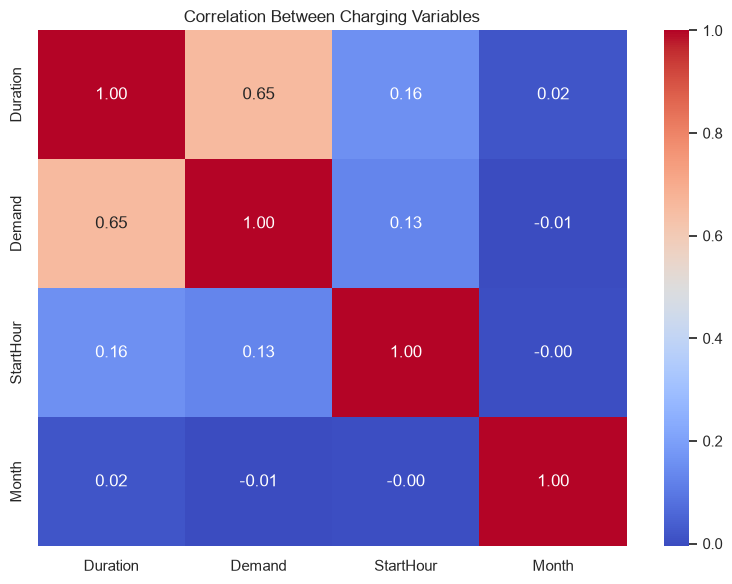

In [35]:
correlation_columns = [
    "Duration",
    "Demand",
    "StartHour",
    "Month"
]

correlation_matrix = df_clean[correlation_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Charging Variables")
plt.tight_layout()

plt.savefig(
    "visualizations/correlation_heatmap.png",
    dpi=300
)
plt.show()

In [36]:
print("========== EV CHARGING ANALYSIS ==========")

print("Total sessions:", len(df_clean))
print("Unique users:", df_clean["UserID"].nunique())
print("Unique chargers:", df_clean["ChargerID"].nunique())
print("Unique locations:", df_clean["Location"].nunique())

print("\nAverage duration:", round(df_clean["Duration"].mean(), 2), "minutes")
print("Median duration:", round(df_clean["Duration"].median(), 2), "minutes")

print("\nAverage demand:", round(df_clean["Demand"].mean(), 2))
print("Median demand:", round(df_clean["Demand"].median(), 2))

print("\nMost active day:")
print(df_clean["DayOfWeek"].value_counts().idxmax())

print("\nMost active hour:")
print(df_clean["StartHour"].value_counts().idxmax())

print("\nMost active location:")
print(df_clean["Location"].value_counts().idxmax())

========== EV CHARGING ANALYSIS ==========
Total sessions: 72108
Unique users: 2321
Unique chargers: 2115
Unique locations: 14

Average duration: 152.73 minutes
Median duration: 114.0 minutes

Average demand: 17.57
Median demand: 14.26

Most active day:
Thursday

Most active hour:
18

Most active location:
public area


In [37]:
print("Missing values after cleaning:")
display(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:", df_clean.duplicated().sum())

print("\nFinal dataset preview:")
display(df_clean.head())

Missing values after cleaning:


UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
StartHour         0
DayOfWeek         0
Month             0
Date              0
TimePeriod        0
dtype: int64


Duplicate rows after cleaning: 0

Final dataset preview:


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,StartHour,DayOfWeek,Month,Date,TimePeriod
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,Thursday,9,2022-09-15,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,Wednesday,9,2022-09-14,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,Wednesday,9,2022-09-14,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,Thursday,9,2022-09-29,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,Sunday,9,2022-09-25,Evening
